# FinPulse India
## Household Financial Vulnerability State Tracking using Hidden Markov Models

**Project type:** Machine Learning — Sequential Data / Hidden Markov Model  
**Dataset period:** 2016–2019  
**Unit of analysis:** Household-year observation  
**Core method:** Gaussian Hidden Markov Model (GaussianHMM)

### Project objective
This project uses annual household observations to identify recurring, unobserved patterns in multidimensional poverty and household dependency indicators. A Hidden Markov Model is used to estimate latent states and the probabilities of transitions between those states over consecutive observed years.

> **Scope:** This is a household vulnerability-state analysis. The dataset does not provide monthly loan repayment histories or a verified loan-default target. Therefore, this notebook does **not** claim to predict loan default or monthly repayment behaviour.

### Selected observation features
- `MDPS` — Multidimensional Poverty Score
- `VMDPS` — Vulnerability to Multidimensional Poverty Score
- `dep_rate` — Dependency rate

Borrowing-related variables are retained in the source dataset for possible descriptive interpretation; they are not used as core HMM observations in this baseline model.

## 1. Environment setup

Run the next cell first. It installs the required packages. If the dataset is already uploaded to the current Colab runtime at `/content/Final_Analytical_data_file.dta`, the notebook will use it. Otherwise, it will prompt you to upload the `.dta` file.

In [1]:
%pip -q install hmmlearn pyreadstat joblib openpyxl

## 2. Imports and reproducibility

In [2]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from hmmlearn.hmm import GaussianHMM

warnings.filterwarnings("ignore", category=RuntimeWarning)

RANDOM_SEEDS = [42, 52, 62]
FEATURES = ["MDPS", "VMDPS", "dep_rate"]
OUTPUT_DIR = Path("/content/finpulse_mentor_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Environment ready.")
print("Output directory:", OUTPUT_DIR)

Environment ready.
Output directory: /content/finpulse_mentor_outputs


## 3. Load the analytical dataset

In [3]:
DATA_PATH = Path("/content/Final_Analytical_data_file.dta")

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("Upload Final_Analytical_data_file.dta")
        uploaded = files.upload()
        uploaded_dta = [name for name in uploaded if name.lower().endswith(".dta")]
        if not uploaded_dta:
            raise FileNotFoundError("No .dta file was uploaded.")
        DATA_PATH = Path("/content") / uploaded_dta[0]
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Place Final_Analytical_data_file.dta in /content "
            "or run this notebook in Google Colab and upload it when prompted."
        )

df = pd.read_stata(DATA_PATH, convert_categoricals=False)

print("DATASET LOADED")
print("=" * 55)
print("File:", DATA_PATH)
print("Shape:", df.shape)
print("Unique households:", df["HH_ID"].nunique() if "HH_ID" in df.columns else "HH_ID missing")
print("Year values:", sorted(df["year"].dropna().unique().tolist()) if "year" in df.columns else "year missing")
display(df.head())

Upload Final_Analytical_data_file.dta


Saving Final_Analytical_data_file.dta to Final_Analytical_data_file.dta
DATASET LOADED
File: /content/Final_Analytical_data_file.dta
Shape: (47437, 115)
Unique households: 32880
Year values: [2016.0, 2017.0, 2018.0, 2019.0]


,HH_ID,state,hr,REGION_TYPE,district,ageyrs,HH_gend,region,hhsize,year,anl_bank_brw,anl_mnylndr_brw,anl_relfrnds_brw,anl_nbfc_brw,anl_shg_brw,anl_mfi_brw,brw_shg_mfi,dep_rate,no_edu,primary_edu,higher_edu,HH_empl,HH_frml_occu,reserve_cat,VMDPS,shg_mfi_pr,shg_mfi_up,MDPS,wrkage,fami_size,STATE,bankbrnch_hr,prop_winfmale_cand,fml_empl,prop_treat_hr,prop_hosp_hr,prop_govtscl_hr,prop_pvtscl_hr,d_year_state1,d_year_state2,d_year_state3,d_year_state4,d_year_state5,d_year_state6,d_year_state7,d_year_state8,d_year_state9,d_year_state10,d_year_state11,d_year_state12,...,d_year_state28,d_year_state29,d_year_state30,d_year_state31,d_year_state32,d_year_state33,d_year_state34,d_year_state35,d_year_state36,d_year_state37,d_year_state38,d_year_state39,d_year_state40,d_year_state41,d_year_state42,d_year_state43,d_year_state44,d_year_state45,d_year_state46,d_year_state47,d_year_state48,d_year_state49,d_year_state50,d_year_state51,d_year_state52,d_year_state53,d_year_state54,d_year_state55,d_year_state56,d_year_state57,d_year_state58,d_year_state59,d_year_state60,d_year_state61,d_year_state62,d_year_state63,d_year_state64,d_year_state65,d_year_state66,d_year_state67,d_year_state68,d_year_state69,d_year_state70,d_year_state71,d_year_state72,d_year_state73,yr_16,yr_17,yr_18,yr_19
0,10002083,Uttar Pradesh,HR 21,URBAN,Kanpur Nagar,45,1.0,1.0,3.0,2019.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.166667,0.0,0.0,0.166667,1.0,0.0,19,0.015884,0.304348,0.0,0.421784,0.012987,0.076659,0.041508,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0.0,0.0,0.0,1.0
1,10002837,Odisha,HR 98,RURAL,Baleshwar,36,0.0,0.0,4.0,2019.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.333333,0.0,0.0,0.333333,1.0,0.0,14,0.016536,0.096154,0.0,0.493424,0.017232,0.110196,0.015842,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0.0,0.0,0.0,1.0
2,10005149,Haryana,HR 9,RURAL,Bhiwani,40,0.0,0.0,4.0,2018.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.166667,0.0,0.0,0.400000,1.0,0.0,6,0.017563,0.142857,0.0,0.234472,0.012091,0.064499,0.027370,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0
3,10005231,Tamil Nadu,HR 73,URBAN,Dindigul,58,0.0,1.0,3.0,2016.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.500000,0.0,0.0,0.066667,1.0,0.0,17,0.025005,0.031250,0.0,0.675177,0.016431,0.070723,0.014889,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0
4,10005231,Tamil Nadu,HR 73,URBAN,Dindigul,60,0.0,1.0,3.0,2017.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.500000,0.0,0.0,0.066667,1.0,0.0,17,0.026204,0.031250,0.0,0.751300,0.017151,0.071216,0.015269,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,1.0,0.0,0.0


## 4. Dataset structure and quality checks

The source is an analytical household dataset covering 2016–2019. The checks below verify the identifiers, year field, selected features, duplicate household-year records, and missing values relevant to this model.

In [4]:
required_columns = ["HH_ID", "year"] + FEATURES
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {missing_columns}")

quality = pd.DataFrame({
    "Check": [
        "Total rows",
        "Total columns",
        "Unique households",
        "Missing household IDs",
        "Missing years",
        "Duplicate household-year pairs"
    ],
    "Result": [
        len(df),
        df.shape[1],
        df["HH_ID"].nunique(),
        int(df["HH_ID"].isna().sum()),
        int(df["year"].isna().sum()),
        int(df.duplicated(["HH_ID", "year"]).sum())
    ]
})
display(quality)

feature_quality = pd.DataFrame({
    "Feature": FEATURES,
    "Data type": [str(df[c].dtype) for c in FEATURES],
    "Missing values": [int(df[c].isna().sum()) for c in FEATURES],
    "Unique values": [int(df[c].nunique(dropna=True)) for c in FEATURES]
})
display(feature_quality)

if df["HH_ID"].isna().any() or df["year"].isna().any():
    raise ValueError("HH_ID or year contains missing values. Resolve identifiers before sequence construction.")

if df.duplicated(["HH_ID", "year"]).any():
    raise ValueError("Duplicate HH_ID-year records detected. Do not silently train on duplicate household-year rows.")

,Check,Result
0,Total rows,47437
1,Total columns,115
2,Unique households,32880
3,Missing household IDs,0
4,Missing years,0
5,Duplicate household-year pairs,0


,Feature,Data type,Missing values,Unique values
0,MDPS,float32,0,25
1,VMDPS,float32,0,16
2,dep_rate,float32,0,46


## 5. Descriptive analysis

The annual means below are pooled year-wise averages. Because the panel is unbalanced, changes in these pooled averages should not automatically be interpreted as within-household changes over time.

In [5]:
analysis_df = df.copy()
for col in FEATURES:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")

analysis_df["year"] = pd.to_numeric(analysis_df["year"], errors="coerce")
analysis_df = analysis_df.dropna(subset=["HH_ID", "year"] + FEATURES).copy()
analysis_df["year"] = analysis_df["year"].astype(int)

print("Rows available for descriptive analysis:", len(analysis_df))
print("\nFeature summary:")
display(analysis_df[FEATURES].describe().T)

annual_trends = analysis_df.groupby("year")[FEATURES].mean().reset_index()
print("\nPooled annual feature means:")
display(annual_trends)

print("\nFeature correlation:")
display(analysis_df[FEATURES].corr())

Rows available for descriptive analysis: 47437

Feature summary:


,count,mean,std,min,25%,50%,75%,max
MDPS,47437.0,0.184851,0.142530,0.0,0.066667,0.166667,0.233333,0.933333
VMDPS,47437.0,0.294813,0.149359,0.0,0.166667,0.233333,0.400000,0.800000
dep_rate,47437.0,0.328246,0.465754,0.0,0.000000,0.000000,0.500000,6.000000



Pooled annual feature means:


,year,MDPS,VMDPS,dep_rate
0,2016,0.264116,0.404756,0.357313
1,2017,0.221584,0.356194,0.324472
2,2018,0.171864,0.274353,0.339388
3,2019,0.152509,0.246788,0.310163



Feature correlation:


,MDPS,VMDPS,dep_rate
MDPS,1.000000,0.430628,0.086662
VMDPS,0.430628,1.000000,0.044864
dep_rate,0.086662,0.044864,1.000000


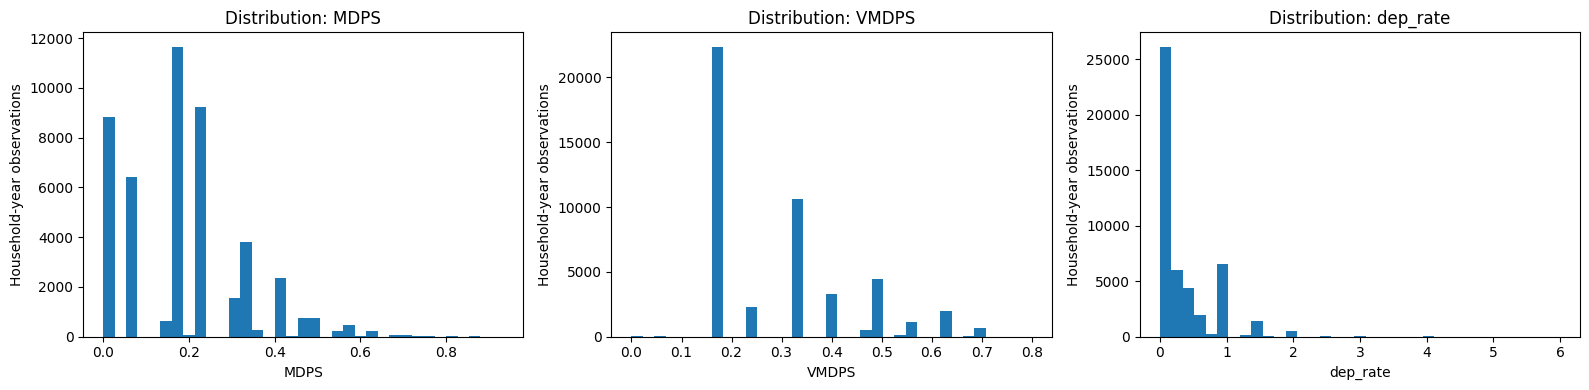

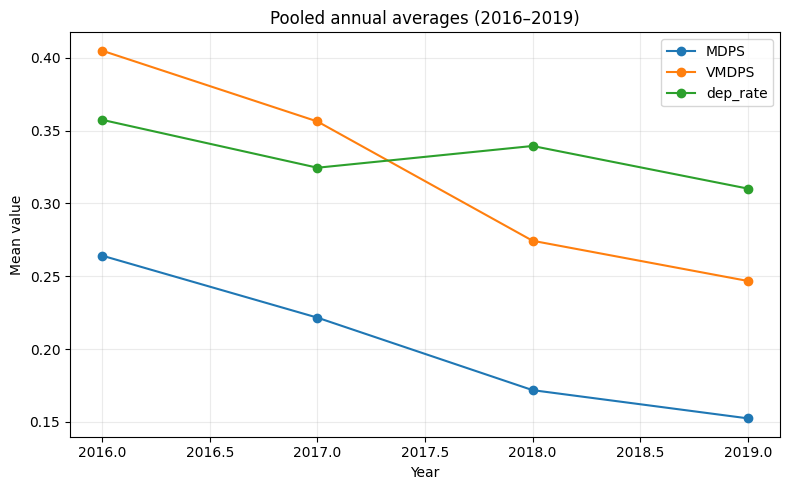

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, FEATURES):
    ax.hist(analysis_df[feature].dropna(), bins=35)
    ax.set_title(f"Distribution: {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Household-year observations")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for feature in FEATURES:
    ax.plot(annual_trends["year"], annual_trends[feature], marker="o", label=feature)
ax.set_title("Pooled annual averages (2016–2019)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean value")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_annual_trends.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Construct consecutive household sequences

An HMM requires ordered observations. Records are grouped by household and sorted by year. A new sequence segment starts whenever the year gap is not exactly one year. Singleton segments are excluded from model fitting because they contain no within-sequence transition.

This avoids treating a gap (for example, 2016 followed by 2018) as if it were a one-year transition.

In [7]:
sequence_segments = []
sequence_metadata = []
sequence_id = 0

for household_id, group in analysis_df.sort_values(["HH_ID", "year"]).groupby("HH_ID", sort=False):
    group = group.sort_values("year").copy()
    year_diff = group["year"].diff()
    split_points = np.where(year_diff.to_numpy()[1:] != 1)[0] + 1
    parts = np.split(group, split_points)

    for part in parts:
        if len(part) >= 2:
            part = part.copy()
            part["sequence_id"] = sequence_id
            sequence_segments.append(part)
            sequence_metadata.append({
                "sequence_id": sequence_id,
                "HH_ID": household_id,
                "start_year": int(part["year"].min()),
                "end_year": int(part["year"].max()),
                "observations": int(len(part))
            })
            sequence_id += 1

if not sequence_segments:
    raise ValueError("No consecutive household sequences of length 2 or more were found.")

hmm_df = pd.concat(sequence_segments, ignore_index=True)
sequence_summary = pd.DataFrame(sequence_metadata)
sequence_lengths = sequence_summary["observations"].astype(int).tolist()

assert sum(sequence_lengths) == len(hmm_df)

print("SEQUENCE CONSTRUCTION")
print("=" * 55)
print("Eligible sequence segments:", len(sequence_lengths))
print("Observations used for HMM:", len(hmm_df))
print("Consecutive-year transitions:", sum(sequence_lengths) - len(sequence_lengths))
print("Households represented:", hmm_df["HH_ID"].nunique())
print("Excluded singleton segments:", int((analysis_df.groupby("HH_ID").size() == 1).sum()), "(household-level count; gaps may also create singleton segments)")
display(sequence_summary.head())

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
/usr/local/li

SEQUENCE CONSTRUCTION
Eligible sequence segments: 9669
Observations used for HMM: 21679
Consecutive-year transitions: 12010
Households represented: 9669
Excluded singleton segments: 21298 (household-level count; gaps may also create singleton segments)


,sequence_id,HH_ID,start_year,end_year,observations
0,0,10005231,2016,2019,4
1,1,10007321,2016,2017,2
2,2,10007964,2018,2019,2
3,3,10008867,2016,2019,4
4,4,10009432,2018,2019,2


## 7. Standardize observations

The Gaussian HMM is fitted on standardized features so that variables with larger numerical scales do not dominate the likelihood solely because of their units. State profiles will later be reported in the original feature units.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(hmm_df[FEATURES].astype(float))

print("Scaled matrix shape:", X_scaled.shape)
print("Sequence lengths:", len(sequence_lengths), "segments")
print("Total sequence observations:", sum(sequence_lengths))

Scaled matrix shape: (21679, 3)
Sequence lengths: 9669 segments
Total sequence observations: 21679


## 8. Train and compare Gaussian HMM models

Candidate models use 2, 3, and 4 hidden states with diagonal Gaussian covariance. For each state count, multiple random initializations are attempted; the run with the highest log-likelihood is retained.

AIC and BIC are approximate information criteria using the parameter count for a diagonal-covariance Gaussian HMM. BIC is used as the primary selection guide, but the selected model must also be inspected for convergence, tiny states, and interpretable emission profiles.

In [10]:
import numpy as np
import pandas as pd
from hmmlearn.hmm import GaussianHMM

# Train a compact 3-state Gaussian HMM
best_model = GaussianHMM(
    n_components=3,
    covariance_type="diag",
    n_iter=150,
    tol=1e-3,
    min_covar=1e-2,
    random_state=42,
    implementation="scaling"
)

best_model.fit(X_scaled, lengths=sequence_lengths)

# Model evaluation
log_likelihood = best_model.score(
    X_scaled,
    lengths=sequence_lengths
)

n_parameters = (
    3 * (3 - 1) +
    (3 - 1) +
    2 * 3 * X_scaled.shape[1]
)

n_observations = len(X_scaled)

aic = 2 * n_parameters - 2 * log_likelihood
bic = np.log(n_observations) * n_parameters - 2 * log_likelihood

model_comparison = pd.DataFrame([{
    "States": 3,
    "Log Likelihood": log_likelihood,
    "Parameters": n_parameters,
    "AIC": aic,
    "BIC": bic,
    "Converged": best_model.monitor_.converged,
    "Iterations": best_model.monitor_.iter
}])

display(model_comparison)

print("HMM TRAINING COMPLETE")
print("Selected states:", best_model.n_components)
print("Converged:", best_model.monitor_.converged)
print("Iterations:", best_model.monitor_.iter)

,States,Log Likelihood,Parameters,AIC,BIC,Converged,Iterations
0,3,-5985.838433,26,12023.676866,12231.263448,True,79


HMM TRAINING COMPLETE
Selected states: 3
Converged: True
Iterations: 79


## 9. Infer hidden states

The Viterbi algorithm assigns the most likely hidden-state path for each independent sequence segment. Posterior state probabilities are also retained as a measure of assignment uncertainty.

In [11]:
selected_k = best_model.n_components
print("Selected number of states:", selected_k)

Selected number of states: 3


In [12]:
hidden_states = best_model.predict(X_scaled, lengths=sequence_lengths)
posterior = best_model.predict_proba(X_scaled, lengths=sequence_lengths)

results_df = hmm_df[["HH_ID", "year", "sequence_id"] + FEATURES].copy()
results_df["hidden_state"] = hidden_states.astype(int)

for state_idx in range(selected_k):
    results_df[f"state_{state_idx}_probability"] = posterior[:, state_idx]

print("Inference complete.")
print("Rows with inferred states:", len(results_df))
display(results_df.head())

Inference complete.
Rows with inferred states: 21679


,HH_ID,year,sequence_id,MDPS,VMDPS,dep_rate,hidden_state,state_0_probability,state_1_probability,state_2_probability
0,10005231,2016,0,0.066667,0.500000,0.0,0,0.911071,8.885662e-02,0.000072
1,10005231,2017,0,0.066667,0.500000,0.0,0,0.977409,2.258228e-02,0.000009
2,10005231,2018,0,0.066667,0.333333,0.0,0,0.999850,3.927513e-05,0.000111
3,10005231,2019,0,0.233333,0.333333,0.5,2,0.000000,0.000000e+00,1.000000
4,10007321,2016,1,0.166667,0.166667,0.0,0,0.999976,7.527523e-08,0.000024


In [13]:
# ==========================================
# FINPULSE INDIA - STATE INTERPRETATION
# ==========================================

import numpy as np
import pandas as pd

# 1. State distribution
state_distribution = (
    results_df["hidden_state"]
    .value_counts()
    .sort_index()
    .rename_axis("Hidden State")
    .reset_index(name="Observations")
)

state_distribution["Percentage"] = (
    state_distribution["Observations"]
    / len(results_df) * 100
).round(2)

print("1. HIDDEN STATE DISTRIBUTION")
display(state_distribution)

# 2. State profiles in original feature units
state_profiles = (
    results_df.groupby("hidden_state")[FEATURES]
    .agg(["mean", "median", "std", "count"])
    .round(4)
)

print("\n2. HIDDEN STATE FEATURE PROFILES")
display(state_profiles)

# 3. Learned transition probability matrix
transition_matrix = pd.DataFrame(
    best_model.transmat_,
    index=[f"From State {i}" for i in range(selected_k)],
    columns=[f"To State {i}" for i in range(selected_k)]
).round(4)

print("\n3. LEARNED TRANSITION MATRIX")
display(transition_matrix)

# 4. Initial state probabilities
initial_probabilities = pd.DataFrame({
    "Hidden State": range(selected_k),
    "Initial Probability": best_model.startprob_.round(4)
})

print("\n4. INITIAL STATE PROBABILITIES")
display(initial_probabilities)

# 5. Basic validation
print("\n5. VALIDATION")
print("Total inferred observations:", len(results_df))
print("Transition matrix row sums:",
      np.round(best_model.transmat_.sum(axis=1), 4))
print("All probabilities valid:",
      np.all(best_model.transmat_ >= 0) and
      np.allclose(best_model.transmat_.sum(axis=1), 1))

1. HIDDEN STATE DISTRIBUTION


,Hidden State,Observations,Percentage
0,0,10883,50.20
1,1,1869,8.62
2,2,8927,41.18



2. HIDDEN STATE FEATURE PROFILES


MDPS                          VMDPS                        dep_rate                       
                mean  median     std  count    mean  median     std  count     mean  median     std  count
hidden_state                                                                                              
0             0.1302  0.1667  0.1161  10883  0.2661  0.2333  0.1088  10883   0.0000  0.0000  0.0000  10883
1             0.3499  0.3333  0.1382   1869  0.5591  0.5667  0.0711   1869   0.0000  0.0000  0.0000   1869
2             0.1999  0.1667  0.1502   8927  0.3060  0.2333  0.1593   8927   0.7154  0.6667  0.4203   8927


3. LEARNED TRANSITION MATRIX


,To State 0,To State 1,To State 2
From State 0,0.9058,0.0000,0.0942
From State 1,0.4141,0.4889,0.0970
From State 2,0.1668,0.0147,0.8185



4. INITIAL STATE PROBABILITIES


,Hidden State,Initial Probability
0,0,0.4555
1,1,0.1150
2,2,0.4295



5. VALIDATION
Total inferred observations: 21679
Transition matrix row sums: [1. 1. 1.]
All probabilities valid: True


FINPULSE INDIA — FINAL RESULTS
Records analysed: 21679
Unique households: 9669
Years covered: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Hidden states: 3
Model converged: True
Training iterations: 79

STATE DISTRIBUTION


,Records,Percentage
Hidden State,,
0,10883,50.20
1,1869,8.62
2,8927,41.18



HIDDEN STATE FEATURE PROFILES


MDPS                   VMDPS                 dep_rate                
                mean  median     std    mean  median     std     mean  median     std
hidden_state                                                                         
0             0.1302  0.1667  0.1161  0.2661  0.2333  0.1088   0.0000  0.0000  0.0000
1             0.3499  0.3333  0.1382  0.5591  0.5667  0.0711   0.0000  0.0000  0.0000
2             0.1999  0.1667  0.1502  0.3060  0.2333  0.1593   0.7154  0.6667  0.4203


LEARNED TRANSITION MATRIX


,State_0,State_1,State_2
State_0,0.9058,0.0000,0.0942
State_1,0.4141,0.4889,0.0970
State_2,0.1668,0.0147,0.8185



YEAR-WISE STATE DISTRIBUTION (%)


hidden_state,0,1,2
year,,,
2016,31.55,23.64,44.81
2017,39.11,17.49,43.40
2018,52.96,5.02,42.02
2019,60.40,2.29,37.31



ANNUAL FEATURE TRENDS


,MDPS,VMDPS,dep_rate
year,,,
2016,0.2635,0.4172,0.3101
2017,0.2260,0.3710,0.2960
2018,0.1576,0.2811,0.3052
2019,0.1432,0.2632,0.2748


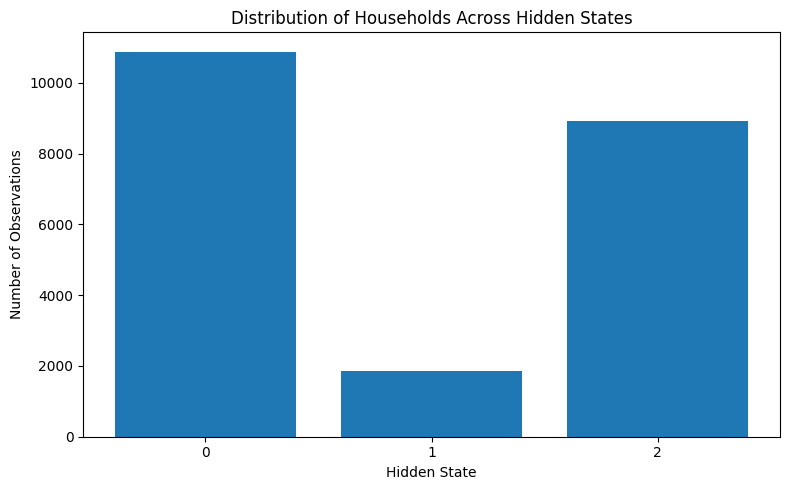

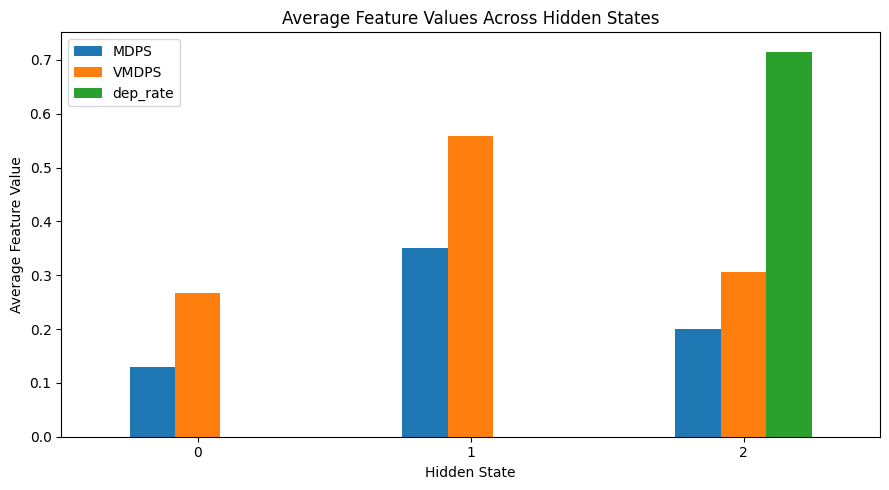

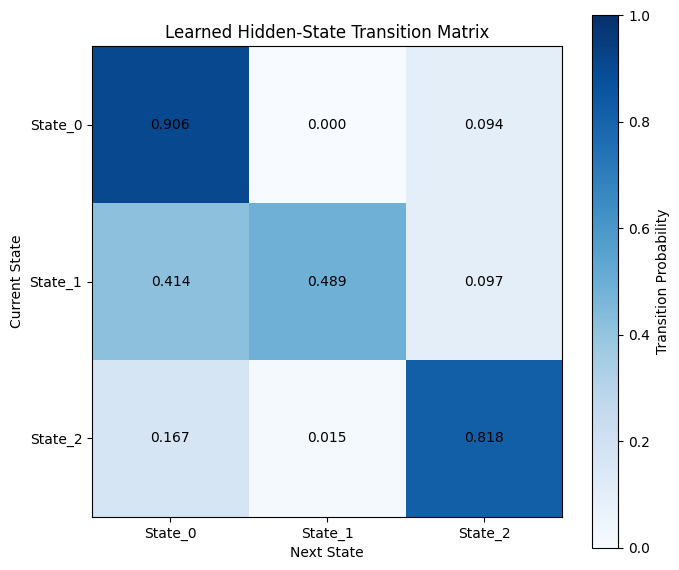

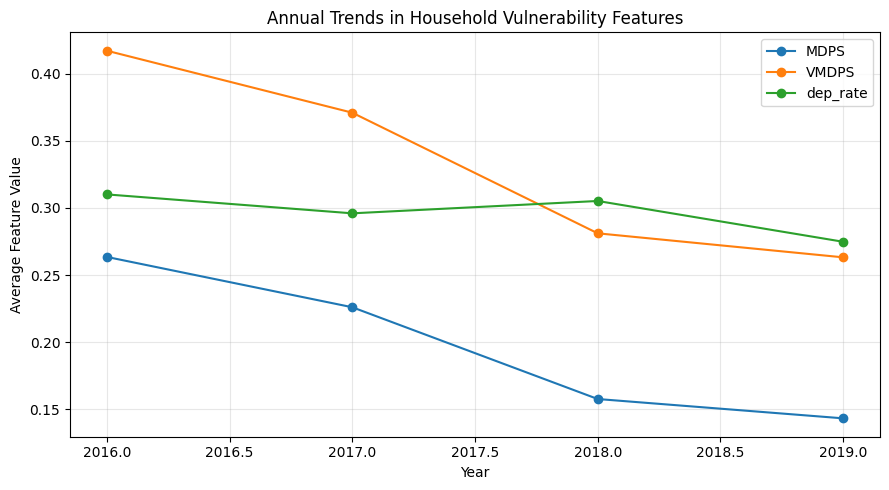


MODEL SUMMARY


,Metric,Value
0,Algorithm,Gaussian Hidden Markov Model
1,Number of Hidden States,3
2,Log Likelihood,-5985.8384
3,AIC,12023.6769
4,BIC,12231.2634
5,Converged,True
6,Iterations,79
7,Observations Analysed,21679
8,Unique Households Analysed,9669



FINAL OUTPUTS CREATED
01_state_distribution.png
02_state_profiles.png
03_transition_matrix.png
04_annual_state_trends.png
04_annual_trends.png
FinPulse_India_Final_Results.xlsx
FinPulse_Mentor_Results.xlsx
finpulse_gaussian_hmm.joblib
finpulse_household_hidden_states.csv

Excel workbook: /content/FinPulse_Final_Results/FinPulse_India_Final_Results.xlsx


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. VALIDATE CURRENT MODEL OUTPUTS
# --------------------------------------------------
required = ["results_df", "best_model", "FEATURES"]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}. Run the previous model cells first.")

if results_df.empty:
    raise RuntimeError("results_df is empty. Hidden-state inference must complete first.")

output_dir = Path("/content/FinPulse_Final_Results")
output_dir.mkdir(parents=True, exist_ok=True)

print("FINPULSE INDIA — FINAL RESULTS")
print("=" * 55)
print("Records analysed:", len(results_df))
print("Unique households:", results_df["HH_ID"].nunique())
print("Years covered:", sorted(results_df["year"].unique()))
print("Hidden states:", best_model.n_components)
print("Model converged:", best_model.monitor_.converged)
print("Training iterations:", best_model.monitor_.iter)

# --------------------------------------------------
# 2. HIDDEN STATE DISTRIBUTION
# --------------------------------------------------
state_distribution = (
    results_df["hidden_state"]
    .value_counts()
    .sort_index()
    .rename("Records")
    .to_frame()
)

state_distribution["Percentage"] = (
    state_distribution["Records"] / len(results_df) * 100
).round(2)

state_distribution.index.name = "Hidden State"

print("\nSTATE DISTRIBUTION")
display(state_distribution)

# --------------------------------------------------
# 3. STATE FEATURE PROFILES
# --------------------------------------------------
state_profiles = (
    results_df.groupby("hidden_state")[FEATURES]
    .agg(["mean", "median", "std"])
    .round(4)
)

print("\nHIDDEN STATE FEATURE PROFILES")
display(state_profiles)

# --------------------------------------------------
# 4. LEARNED TRANSITION MATRIX
# --------------------------------------------------
state_names = [f"State_{i}" for i in range(best_model.n_components)]

transition_matrix = pd.DataFrame(
    best_model.transmat_,
    index=state_names,
    columns=state_names
).round(4)

print("\nLEARNED TRANSITION MATRIX")
display(transition_matrix)

# --------------------------------------------------
# 5. YEAR-WISE STATE DISTRIBUTION
# --------------------------------------------------
yearly_states = pd.crosstab(
    results_df["year"],
    results_df["hidden_state"],
    normalize="index"
) * 100

yearly_states = yearly_states.round(2)

print("\nYEAR-WISE STATE DISTRIBUTION (%)")
display(yearly_states)

# --------------------------------------------------
# 6. YEAR-WISE FEATURE TRENDS
# --------------------------------------------------
annual_trends = (
    results_df.groupby("year")[FEATURES]
    .mean()
    .round(4)
)

print("\nANNUAL FEATURE TRENDS")
display(annual_trends)

# --------------------------------------------------
# 7. VISUALIZATION 1 — STATE DISTRIBUTION
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.bar(
    state_distribution.index.astype(str),
    state_distribution["Records"]
)
plt.title("Distribution of Households Across Hidden States")
plt.xlabel("Hidden State")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.savefig(output_dir / "01_state_distribution.png", dpi=300)
plt.show()

# --------------------------------------------------
# 8. VISUALIZATION 2 — STATE FEATURE PROFILES
# --------------------------------------------------
profile_means = results_df.groupby("hidden_state")[FEATURES].mean()

ax = profile_means.plot(
    kind="bar",
    figsize=(9, 5)
)
ax.set_title("Average Feature Values Across Hidden States")
ax.set_xlabel("Hidden State")
ax.set_ylabel("Average Feature Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "02_state_profiles.png", dpi=300)
plt.show()

# --------------------------------------------------
# 9. VISUALIZATION 3 — TRANSITION MATRIX
# --------------------------------------------------
plt.figure(figsize=(7, 6))
plt.imshow(best_model.transmat_, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Transition Probability")
plt.xticks(range(len(state_names)), state_names)
plt.yticks(range(len(state_names)), state_names)

for i in range(best_model.n_components):
    for j in range(best_model.n_components):
        plt.text(
            j, i,
            f"{best_model.transmat_[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.title("Learned Hidden-State Transition Matrix")
plt.xlabel("Next State")
plt.ylabel("Current State")
plt.tight_layout()
plt.savefig(output_dir / "03_transition_matrix.png", dpi=300)
plt.show()

# --------------------------------------------------
# 10. VISUALIZATION 4 — ANNUAL FEATURE TRENDS
# --------------------------------------------------
plt.figure(figsize=(9, 5))

for feature in FEATURES:
    plt.plot(
        annual_trends.index,
        annual_trends[feature],
        marker="o",
        label=feature
    )

plt.title("Annual Trends in Household Vulnerability Features")
plt.xlabel("Year")
plt.ylabel("Average Feature Value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "04_annual_trends.png", dpi=300)
plt.show()

# --------------------------------------------------
# 11. MODEL COMPARISON SUMMARY
# --------------------------------------------------
model_summary = pd.DataFrame({
    "Metric": [
        "Algorithm",
        "Number of Hidden States",
        "Log Likelihood",
        "AIC",
        "BIC",
        "Converged",
        "Iterations",
        "Observations Analysed",
        "Unique Households Analysed"
    ],
    "Value": [
        "Gaussian Hidden Markov Model",
        best_model.n_components,
        round(best_model.score(X_scaled, sequence_lengths), 4),
        round(model_comparison.iloc[0]["AIC"], 4),
        round(model_comparison.iloc[0]["BIC"], 4),
        best_model.monitor_.converged,
        best_model.monitor_.iter,
        len(results_df),
        results_df["HH_ID"].nunique()
    ]
})

print("\nMODEL SUMMARY")
display(model_summary)

# --------------------------------------------------
# 12. EXPORT FINAL EXCEL WORKBOOK
# --------------------------------------------------
excel_path = output_dir / "FinPulse_India_Final_Results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    model_summary.to_excel(writer, sheet_name="Model Summary", index=False)
    state_distribution.to_excel(writer, sheet_name="State Distribution")
    state_profiles.to_excel(writer, sheet_name="State Profiles")
    transition_matrix.to_excel(writer, sheet_name="Transition Matrix")
    yearly_states.to_excel(writer, sheet_name="Yearly States")
    annual_trends.to_excel(writer, sheet_name="Annual Trends")
    results_df.to_excel(writer, sheet_name="Household Hidden States", index=False)

print("\nFINAL OUTPUTS CREATED")
for file in sorted(output_dir.iterdir()):
    print(file.name)

print("\nExcel workbook:", excel_path)

In [22]:
print("FINAL DATASET VALIDATION")
print("=" * 45)

print("Total inferred observations:", len(results_df))
print("Unique households:", results_df["HH_ID"].nunique())
print("Independent sequence segments:", results_df["sequence_id"].nunique())

print("\nObservations by hidden state:")
display(
    results_df["hidden_state"]
    .value_counts()
    .sort_index()
    .rename_axis("Hidden State")
    .to_frame("Observations")
)

print("\nFeature profiles:")
display(
    results_df.groupby("hidden_state")[FEATURES]
    .mean()
    .round(4)
)

print("\nTransition matrix:")
display(
    pd.DataFrame(
        best_model.transmat_,
        index=[f"From State {i}" for i in range(selected_k)],
        columns=[f"To State {i}" for i in range(selected_k)]
    ).round(4)
)

FINAL DATASET VALIDATION
Total inferred observations: 21679
Unique households: 9669
Independent sequence segments: 9669

Observations by hidden state:


,Observations
Hidden State,
0,10883
1,1869
2,8927



Feature profiles:


,MDPS,VMDPS,dep_rate
hidden_state,,,
0,0.1302,0.2661,0.0000
1,0.3499,0.5591,0.0000
2,0.1999,0.3060,0.7154



Transition matrix:


,To State 0,To State 1,To State 2
From State 0,0.9058,0.0000,0.0942
From State 1,0.4141,0.4889,0.0970
From State 2,0.1668,0.0147,0.8185


## 10. Interpret state profiles

Hidden-state IDs are arbitrary labels assigned by the algorithm. Do not call State 0 “low vulnerability” or State 1 “high vulnerability” based on the numeric ID alone. Interpret states using their feature means, medians, variability, and occupancy.

In [16]:
state_profiles = results_df.groupby("hidden_state")[FEATURES].agg(["count", "mean", "median", "std"])
state_counts = results_df["hidden_state"].value_counts().sort_index()
state_distribution = pd.DataFrame({
    "hidden_state": state_counts.index.astype(int),
    "observations": state_counts.values,
    "percentage": (state_counts.values / len(results_df) * 100)
})

display(state_distribution)
display(state_profiles)

state_means = results_df.groupby("hidden_state")[FEATURES].mean()
display(state_means)

,hidden_state,observations,percentage
0,0,10883,50.200655
1,1,1869,8.621246
2,2,8927,41.178099


MDPS                                VMDPS                               dep_rate                              
              count      mean    median       std  count      mean    median       std    count      mean    median       std
hidden_state                                                                                                                 
0             10883  0.130200  0.166667  0.116134  10883  0.266112  0.233333  0.108795    10883  0.000000  0.000000  0.000000
1              1869  0.349866  0.333333  0.138242   1869  0.559105  0.566667  0.071104     1869  0.000000  0.000000  0.000000
2              8927  0.199892  0.166667  0.150215   8927  0.305952  0.233333  0.159267     8927  0.715392  0.666667  0.420281

,MDPS,VMDPS,dep_rate
hidden_state,,,
0,0.130200,0.266112,0.000000
1,0.349866,0.559105,0.000000
2,0.199892,0.305952,0.715392


## 11. Learned transition matrix

The transition matrix contains the model-estimated probability of moving from one hidden state in year *t* to another hidden state in the next consecutive observed year. Each row should sum to approximately 1.

These are model-estimated transition probabilities, not causal effects.

In [18]:
transition_matrix = pd.DataFrame(
    best_model.transmat_,
    index=[f"From state {i}" for i in range(selected_k)],
    columns=[f"To state {i}" for i in range(selected_k)]
)

display(transition_matrix)
print("Row sums:")
display(transition_matrix.sum(axis=1).to_frame("row_sum"))

,To state 0,To state 1,To state 2
From state 0,0.905763,3.369837e-40,0.094237
From state 1,0.414133,4.888667e-01,0.097000
From state 2,0.166798,1.471951e-02,0.818482


Row sums:


,row_sum
From state 0,1.0
From state 1,1.0
From state 2,1.0


## 12. Household-level summary

The household-level table summarizes the observations available for each household in the HMM inference sample. A dominant state is the most frequently assigned state among that household's included observations; it is a descriptive summary, not a permanent household classification.

In [20]:
def mode_or_nan(values):
    modes = pd.Series(values).mode()
    return int(modes.iloc[0]) if len(modes) else np.nan

household_summary = (
    results_df.groupby("HH_ID")
    .agg(
        observations=("year", "count"),
        first_observed_year=("year", "min"),
        last_observed_year=("year", "max"),
        distinct_states=("hidden_state", "nunique"),
        dominant_state=("hidden_state", mode_or_nan)
    )
    .reset_index()
)

display(household_summary.head(10))
print("Households in inference sample:", len(household_summary))

,HH_ID,observations,first_observed_year,last_observed_year,distinct_states,dominant_state
0,10005231,4,2016,2019,2,0
1,10007321,2,2016,2017,1,0
2,10007964,2,2018,2019,1,0
3,10008867,4,2016,2019,1,0
4,10009432,2,2018,2019,1,2
5,10010104,3,2016,2018,1,2
6,10012443,2,2017,2018,1,0
7,10017022,2,2018,2019,1,2
8,10017196,2,2018,2019,1,0
9,10018915,3,2017,2019,1,0


Households in inference sample: 9669


# Conclusion

FinPulse India demonstrates how Hidden Markov Models can be applied to household-level longitudinal survey data to identify latent financial vulnerability patterns.

The project uses household observations from the Consumer Pyramids Household Survey (CPHS), covering the period 2016–2019. Three features were selected for modelling: Multidimensional Poverty Score (MDPS), Vulnerability to Multidimensional Poverty Score (VMDPS), and dependency rate.

A Gaussian Hidden Markov Model was trained on consecutive annual household observation sequences. The selected three-state model converged successfully after 79 iterations and inferred three distinct latent household vulnerability patterns.

The identified states indicate:
- **State 0:** Relatively lower observed poverty and vulnerability scores.
- **State 1:** Higher observed poverty and vulnerability scores.
- **State 2:** Higher dependency rates alongside moderate poverty and vulnerability scores.

The learned transition matrix provides estimates of the probability of households moving between these latent states across consecutive observed years. High self-transition probabilities for States 0 and 2 indicate persistence in these inferred patterns.

## Limitations

1. The dataset covers 2016–2019 and contains annual rather than monthly observations.
2. The household panel is unbalanced, with different households observed for different numbers of years.
3. The HMM identifies latent vulnerability patterns; it does not directly predict loan defaults or repayment behaviour.
4. The inferred states represent statistical groupings and should not be interpreted as official financial classifications.
5. Results are based on the matched analytical sample and should not automatically be generalized to every household in India.

## Future Scope

- Incorporating additional socioeconomic and borrowing-related variables.
- Evaluating state stability across different model configurations.
- Extending the analysis with newer longitudinal household datasets.
- Developing a household vulnerability monitoring dashboard.

**Final Outcome:** FinPulse India demonstrates the application of sequential probabilistic modelling to identify and analyse changing household vulnerability patterns using a Gaussian Hidden Markov Model.